# Выявление всплесков обращений клиентов RUDATA

НАЗВАНИЕ ПРОЕКТА: Интеллектуальная классификация и анализ клиентских обращений (задача 2.2.3), блок «всплески»

ОПИСАНИЕ. После классификации система отслеживает, сколько обращений приходит по каждому интерфейсу,
продукту, тематике и их сочетаниям. Если по какому-то значению за день или за час пришло нетипично много обращений,
формируется уведомление: окно, признак, текущее количество и обычный уровень. Так поддержка узнаёт о сбое
или массовой проблеме по росту обращений, не дожидаясь, пока это заметит оператор.

Требования из описания данных:
- поток обрабатывается в порядке поступления; день или час без обращений — это ноль, а не пропуск;
- обычный уровень считается **только по прошлому**: будущее для нормы не используется;
- в начале истории нужен период накопления нормы, в нём уведомлений нет;
- нужно показать и найденные всплески, и ложные срабатывания;
- оценивать отдельно механизм на эталонной разметке и сквозной сценарий на предсказанных классах.

## Перевод задачи на язык анализа данных

Вид задачи: поиск аномалий во временных рядах, без учителя — флагов и расписания инцидентов в данных нет

Объект: пара «окно × значение признака», например «9 сентября, тематика PERFORMANCE»
или «9 сентября, 10:00–11:00, тематика PERFORMANCE»

Что считаем: число обращений за окно по каждому значению

Признаки, по которым ищем всплески:
- каждое поле отдельно: интерфейс, продукт, тематика;
- сочетания «интерфейс × тематика» и «продукт × тематика» — они точнее показывают, что именно случилось:
  не просто «много обращений про API», а «много жалоб на скорость API».

Окно — две версии:
- **календарный день**: когда день закончился, его число сравнивается с нормой — сводка по итогам дня;
- **календарный час**: когда закончился час, его число сравнивается с нормой — уведомление приходит
  в течение рабочего дня, вскоре после начала роста.

Норма: среднее число обращений за 28 предыдущих дней **того же типа** — будни сравниваются с буднями,
выходные с выходными. Для часа берётся тот же час суток: 10:00–11:00 во вторник сравнивается
с 10:00–11:00 прошлых будней.

## Загрузка необходимых библиотек

In [1]:
# Общее
import pandas as pd  # работа с датафреймами
import numpy as np  # математика
from matplotlib import pyplot as plt  # графики
import json  # прогнозы языковой модели
import math  # вероятность по распределению Пуассона
from datetime import timedelta  # сдвиг на 1–28 дней назад для нормы

pd.set_option('display.max_colwidth', 200)  # показываем тексты обращений целиком

Константы

In [2]:
FIELDS = ['interface', 'product', 'topic']
FEATURES = [['interface'], ['product'], ['topic'], ['interface', 'topic'], ['product', 'topic']]  # что отслеживаем

BASELINE_DAYS = 28  # норма — по 28 предыдущим дням
WARMUP_DAYS = 28  # первые 28 дней истории — накопление нормы, без уведомлений

MIN_RATIO = 2  # всплеск — хотя бы вдвое больше нормы
MIN_BASELINE = 0.5  # если в норме почти ноль, считаем её равной 0,5 обращения за окно — чтобы не делить на ноль

# остальные пороги зависят от окна: за час обращений в десятки раз меньше, а проверок в 24 раза больше
WINDOWS = {
    'date': {'min_count': 10, 'alpha': 0.0001},  # не меньше 10 обращений за день, вероятность случайно — меньше 0,01%
    'hour': {'min_count': 5, 'alpha': 0.000001},  # не меньше 5 за час, вероятность случайно — меньше 0,0001%
}

## Загрузка данных

In [3]:
appeals = pd.read_csv('data/raw/appeals.csv', encoding='utf-8-sig', parse_dates=['created_at'])
moscow_time = appeals['created_at'].dt.tz_convert('Europe/Moscow')
appeals['date'] = moscow_time.dt.date  # день поступления по Москве
appeals['hour'] = moscow_time.dt.floor('h').dt.tz_localize(None)  # час поступления по Москве: 10:00 — это 10:00–11:00

# полный календарь: день без обращений тоже входит в поток — с нулём
days = list(pd.date_range(appeals['date'].min(), appeals['date'].max()).date)
alerts_start = days[WARMUP_DAYS]

display(f'Обращений {len(appeals)}, дней {len(days)}: {days[0]} — {days[-1]}')
display(f'Накопление нормы: {days[0]} — {days[WARMUP_DAYS - 1]}, уведомления — с {alerts_start}')

'Обращений 4765, дней 183: 2026-04-01 — 2026-09-30'

'Накопление нормы: 2026-04-01 — 2026-04-28, уведомления — с 2026-04-29'

## Поток обращений по дням

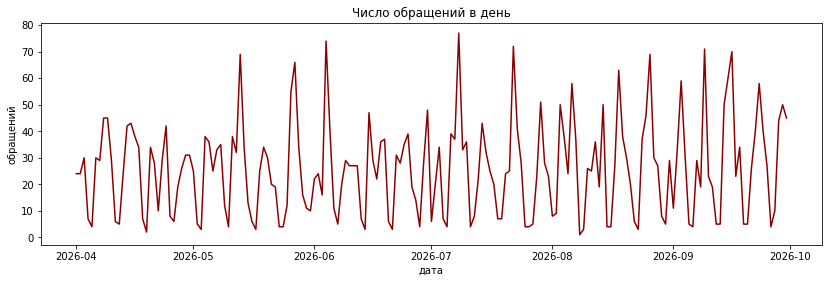

In [4]:
daily = appeals.groupby('date').size().reindex(days, fill_value=0)

daily.plot(figsize=(14, 4), color='darkred')
plt.title('Число обращений в день')
plt.xlabel('дата')
plt.ylabel('обращений')
plt.show()

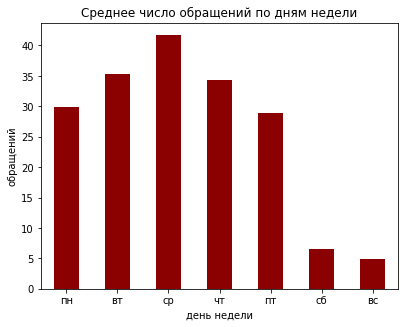

,0
пн,29.8
вт,35.4
ср,41.7
чт,34.3
пт,28.9
сб,6.6
вс,4.9


In [5]:
weekday_names = ['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс']
by_weekday = daily.groupby([weekday_names[d.weekday()] for d in daily.index]).mean().reindex(weekday_names)

by_weekday.plot(kind='bar', color='darkred')
plt.title('Среднее число обращений по дням недели')
plt.xlabel('день недели')
plt.ylabel('обращений')
plt.xticks(rotation=0)
plt.show()

by_weekday.round(1)

**Вывод:** в будни приходит 29–42 обращения в день, в выходные — 5–7. Если сравнивать понедельник
с нормой, в которую входят выходные, каждый понедельник будет выглядеть всплеском. Поэтому норма считается
отдельно для будней и для выходных

## Метод

**Шаг 1. Число обращений за окно.** Для каждого значения признака — таблица «окно × значение»,
где окно — день или час. Окна без обращений заполняем нулями

In [6]:
def counts_by(data, feature, window='date'):
    # значение признака: одно поле («API») или сочетание полей («API × PERFORMANCE»)
    value = data[feature].astype(str).agg(' × '.join, axis=1)
    return data.groupby([data[window], value]).size().unstack(fill_value=0).reindex(periods_of(data, window), fill_value=0)


def periods_of(data, window='date'):
    # полный календарь окон от первого до последнего дня данных: все дни или все 24 часа каждого дня
    first, last = data['date'].min(), data['date'].max()
    if window == 'date':
        return [day for day in days if first <= day <= last]
    return list(pd.date_range(first, pd.Timestamp(last) + pd.Timedelta(hours=23), freq='h'))


counts_by(appeals, ['topic']).head()

,AUTH_ACCESS,AVAILABILITY,CONFIG_INTEGRATION,CONTRACT,DATA_DISCREPANCY,DATA_MISSING,FEATURE_REQUEST,FOLLOW_UP,HOW_TO,INSTALL_UPDATE,METHODOLOGY,PERFORMANCE,UNKNOWN
date,,,,,,,,,,,,,
2026-04-01,3,3,1,1,1,3,1,1,4,0,3,2,1
2026-04-02,2,1,2,2,1,1,3,0,3,0,2,6,1
2026-04-03,3,5,3,1,1,8,2,0,2,1,1,3,0
2026-04-04,3,0,0,0,0,0,1,0,0,0,1,1,1
2026-04-05,0,0,1,1,0,0,0,0,0,0,1,1,0


**Шаг 2. Норма — только по прошлому.** Для каждого окна берём то же окно 1–28 дней назад: для дня —
28 предыдущих дней, для часа — тот же час суток в каждый из 28 предыдущих дней. Оставляем окна того же типа
(будни или выходные) и считаем среднее. Само окно и всё, что после него, в норму не входят

In [7]:
def baseline(counts):
    values = counts.to_numpy(dtype=float)
    position = {period: i for i, period in enumerate(counts.index)}  # номер строки каждого окна
    norm = np.full(values.shape, np.nan)
    for i, period in enumerate(counts.index):
        past = [period - timedelta(days=k) for k in range(1, BASELINE_DAYS + 1)]  # то же окно 1–28 дней назад
        same_type = [position[p] for p in past
                     if p in position and (p.weekday() >= 5) == (period.weekday() >= 5)]  # будни с буднями, выходные с выходными
        if same_type:
            norm[i] = values[same_type].mean(axis=0)
    return pd.DataFrame(norm, index=counts.index, columns=counts.columns)

**Шаг 3. Нетипично ли много.** Число обращений колеблется само по себе: если обычно приходит 2 в день,
то 4 — вполне обычный день. Чтобы отличить случайное колебание от всплеска, используем распределение
Пуассона — стандартную модель для числа событий за период. Оно отвечает на вопрос: **какова вероятность
получить столько обращений или больше, если в среднем их столько, сколько в норме?**

Например, при норме 2 обращения в день вероятность получить 4 или больше — около 14% (обычный день),
а 10 или больше — около 0,005% (всплеск).

Уведомление формируется, если выполнены все три условия:
- обращений не меньше `min_count`: 10 за день или 5 за час — единичные колебания малых значений не важны для поддержки;
- обращений хотя бы в `MIN_RATIO` = 2 раза больше нормы;
- вероятность получить столько случайно меньше `alpha`: 0,01% для дня и 0,0001% для часа. Для часа порог строже,
  потому что проверок в 24 раза больше — подробнее в разделе про почасовое окно.

In [8]:
def poisson_tail(count, rate):
    """Вероятность получить count или больше обращений, если в среднем их rate"""
    below = sum(math.exp(-rate) * rate ** k / math.factorial(k) for k in range(count))
    return max(0.0, 1 - below)


display(f'Норма 2 в день: P(≥4) = {poisson_tail(4, 2):.1%}, P(≥10) = {poisson_tail(10, 2):.4%}')

'Норма 2 в день: P(≥4) = 14.3%, P(≥10) = 0.0046%'

In [9]:
def detect(data, start, window='date', alpha=None, min_count=None):
    alpha = alpha or WINDOWS[window]['alpha']
    min_count = min_count or WINDOWS[window]['min_count']
    start = pd.Timestamp(start) if window == 'hour' else start  # для часа — с полуночи первого дня
    rows = []
    for feature in FEATURES:
        counts = counts_by(data, feature, window)
        norm = baseline(counts)
        for period in counts.index:
            if period < start:
                continue
            for value in counts.columns[counts.loc[period] >= min_count]:  # проверяем только значения, где обращений достаточно
                count, usual = int(counts.at[period, value]), norm.at[period, value]
                rate = max(usual, MIN_BASELINE)
                if count >= MIN_RATIO * rate:
                    p_value = poisson_tail(count, rate)
                    if p_value < alpha:
                        rows.append({**window_of(period, window), 'feature': ' × '.join(feature), 'value': value,
                                     'count': count, 'usual': round(usual, 1), 'ratio': round(count / rate, 1),
                                     'p_value': p_value})
    return pd.DataFrame(rows)


def window_of(period, window):
    # для дня — дата; для часа — дата и интервал «10:00–11:00»
    if window == 'date':
        return {'date': period}
    return {'date': period.date(), 'hour': f'{period:%H:00}–{period + pd.Timedelta(hours=1):%H:00}'}


def times_word(ratio):
    # «в 2 раза», «в 3,8 раза», но «в 5 раз», «в 100 раз»
    if ratio != int(ratio):
        return 'раза'
    return 'раза' if int(ratio) % 10 in (2, 3, 4) and int(ratio) % 100 not in (12, 13, 14) else 'раз'


def notification(alert):
    hourly = 'hour' in alert  # у почасовых уведомлений есть интервал hour
    name = 'час' if hourly else 'день'
    when = f'{alert["date"]:%d.%m.%Y}' + (f' {alert["hour"]}' if hourly else '')
    usual = 'меньше 1' if alert['usual'] < 1 else f'{alert["usual"]:.1f}'.replace('.', ',')
    ratio = f'{alert["ratio"]:g}'.replace('.', ',')
    return (f'{when} | {alert["feature"]} = {alert["value"]}: обращений за {name} — {alert["count"]}, '
            f'обычно {usual} в {name}, в {ratio} {times_word(alert["ratio"])} больше нормы')

## Всплески на эталонной разметке

Сначала проверяем сам механизм — на правильных метках из разметки, без ошибок классификации

In [10]:
alerts = detect(appeals, alerts_start)

display(f'Уведомлений: {len(alerts)}, дней с уведомлениями: {alerts["date"].nunique()}')
alerts.groupby('feature').size()

'Уведомлений: 63, дней с уведомлениями: 15'

,0
feature,
interface,13
interface × topic,14
product,12
product × topic,12
topic,12


Один инцидент обычно поднимает сразу несколько признаков: например, сбой API в один день даёт всплеск
и по интерфейсу API, и по продукту NO_PRODUCT, и по сочетанию «API × PERFORMANCE». Поэтому смотрим сводку
по дням: самое точное уведомление за день — сочетание, если оно сработало, иначе отдельное поле

In [11]:
summary = (alerts.assign(is_combination=alerts['feature'].str.contains('×'))
           .sort_values(['is_combination', 'ratio'], ascending=False)
           .groupby('date').head(1).sort_values('date'))
summary[['date', 'feature', 'value', 'count', 'usual', 'ratio']]

,date,feature,value,count,usual,ratio
51,2026-05-13,product × topic,RD_SCORE × DATA_MISSING,40,0.4,80.0
1,2026-05-27,interface,API,14,3.7,3.8
38,2026-06-04,interface × topic,EXCEL_ADDIN × DATA_MISSING,35,0.4,70.0
39,2026-07-08,interface × topic,API × DATA_MISSING,46,1.2,36.8
40,2026-07-22,interface × topic,EFIR × AUTH_ACCESS,31,0.5,62.0
41,2026-08-03,interface × topic,EXCEL_TEMPLATE × METHODOLOGY,11,0.0,22.0
42,2026-08-04,interface × topic,EXCEL_TEMPLATE × HOW_TO,10,0.2,20.0
43,2026-08-06,interface × topic,WEB × PERFORMANCE,38,0.0,76.0
44,2026-08-18,interface × topic,WEB × AUTH_ACCESS,45,0.6,75.0
45,2026-08-26,interface × topic,EXCEL_ADDIN × AUTH_ACCESS,32,1.0,30.5


Уведомления в том виде, в каком их получит поддержка

In [12]:
for _, alert in summary.iterrows():
    print(notification(alert))

13.05.2026 | product × topic = RD_SCORE × DATA_MISSING: обращений за день — 40, обычно меньше 1 в день, в 80 раз больше нормы
27.05.2026 | interface = API: обращений за день — 14, обычно 3,7 в день, в 3,8 раза больше нормы
04.06.2026 | interface × topic = EXCEL_ADDIN × DATA_MISSING: обращений за день — 35, обычно меньше 1 в день, в 70 раз больше нормы
08.07.2026 | interface × topic = API × DATA_MISSING: обращений за день — 46, обычно 1,2 в день, в 36,8 раза больше нормы
22.07.2026 | interface × topic = EFIR × AUTH_ACCESS: обращений за день — 31, обычно меньше 1 в день, в 62 раза больше нормы
03.08.2026 | interface × topic = EXCEL_TEMPLATE × METHODOLOGY: обращений за день — 11, обычно меньше 1 в день, в 22 раза больше нормы
04.08.2026 | interface × topic = EXCEL_TEMPLATE × HOW_TO: обращений за день — 10, обычно меньше 1 в день, в 20 раз больше нормы
06.08.2026 | interface × topic = WEB × PERFORMANCE: обращений за день — 38, обычно меньше 1 в день, в 76 раз больше нормы
18.08.2026 | inte

Как выглядят всплески на графике: число обращений по сочетанию по дням, норма и дни с уведомлениями

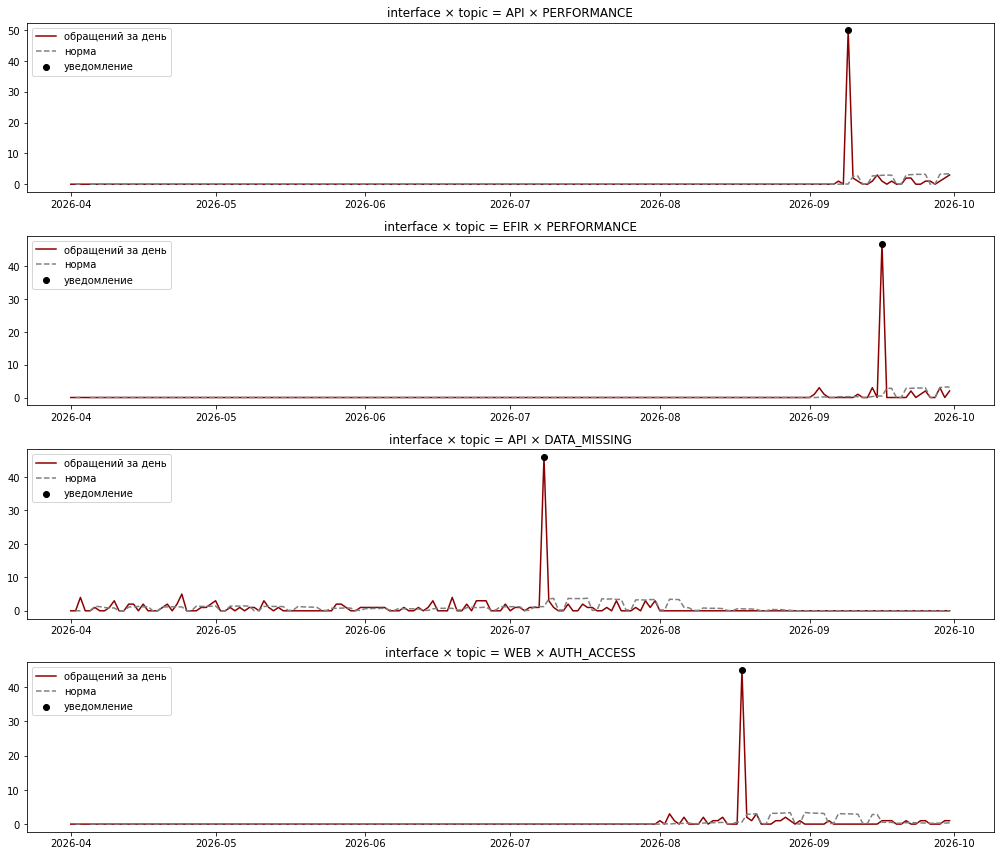

In [13]:
examples = summary.sort_values('count', ascending=False).head(4)

fig, axes = plt.subplots(nrows=len(examples), ncols=1, figsize=(14, 3 * len(examples)))
for ax, (_, alert) in zip(axes, examples.iterrows()):
    feature = alert['feature'].split(' × ')
    counts = counts_by(appeals, feature)[alert['value']]
    norm = baseline(counts_by(appeals, feature))[alert['value']]
    ax.plot(counts.index, counts.values, color='darkred', label='обращений за день')
    ax.plot(norm.index, norm.values, color='grey', linestyle='--', label='норма')
    hits = alerts[(alerts['feature'] == alert['feature']) & (alerts['value'] == alert['value'])]
    ax.scatter(hits['date'], hits['count'], color='black', zorder=3, label='уведомление')
    ax.set_title(f'{alert["feature"]} = {alert["value"]}')
    ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

Что стоит за всплеском: обращения самого крупного из них

In [14]:
top = summary.sort_values('count', ascending=False).iloc[0]
feature = top['feature'].split(' × ')
in_spike = appeals[(appeals['date'] == top['date'])
                   & (appeals[feature].astype(str).agg(' × '.join, axis=1) == top['value'])]
display(notification(top))
in_spike[['created_at', 'client_id', 'text']].head(5)

'09.09.2026 | interface × topic = API × PERFORMANCE: обращений за день — 50, обычно меньше 1 в день, в 100 раз больше нормы'

,created_at,client_id,text
4053,2026-09-09 10:09:11+03:00,rd_user_0147,"Добрый день.\nAPI RUDATA, наш программный клиент. Запрос истории цен всё же завершается успешно, но задержка выросла в несколько раз. Просим проверить время ответа.\nОтвет нужен для дальнейшей работы."
4054,2026-09-09 10:11:27+03:00,rd_user_0125,"Здравствуйте.\n\nИнтеграция с RUDATA идёт через HTTP API. Раньше ответ по списку из 18 инструментов приходил быстро, теперь занимает 45 секунд. Код 200, JSON полный.\n\nВопрос возник в ходе подготовки рабочего отчёта.\n\nПо возможности ответьте в этой переписке."
4055,2026-09-09 10:15:35+03:00,rd_user_0224,"Интеграция с RUDATA идёт через HTTP API. Раньше ответ по списку из 8 инструментов приходил быстро, теперь занимает 45 секунд. Код 200, JSON полный. Уточнения можно прислать ответом на это сообщение."
4057,2026-09-09 10:26:35+03:00,rd_user_0172,"Отправляю HTTP-запросы к API RUDATA. Запрос истории цен всё же завершается успешно, но задержка выросла в несколько раз. Просим проверить время ответа. По возможности ответьте в этой переписке."
4058,2026-09-09 10:27:33+03:00,rd_user_0114,"Работаем с REST API RUDATA. Запрос истории цен всё же завершается успешно, но задержка выросла в несколько раз. Просим проверить время ответа."


### Ложные срабатывания

Флагов заложенных инцидентов в данных нет, поэтому полноту обнаружения доказать нельзя. Но можно оценить,
сколько срабатываний ожидается **чисто случайно**. Каждая пара «день × значение» — одна проверка.
Если всплеска нет, каждая проверка случайно срабатывает с вероятностью не больше `alpha`, поэтому
ожидаемое число ложных срабатываний — не больше «число проверок × alpha»

In [15]:
n_checks = sum(counts_by(appeals, feature).shape[1] for feature in FEATURES) * len([d for d in days if d >= alerts_start])
display(f'Проверок за период: {n_checks}, ожидаемо случайных срабатываний — не больше {n_checks * WINDOWS["date"]["alpha"]:.1f}')

'Проверок за период: 25265, ожидаемо случайных срабатываний — не больше 2.5'

Как меняется результат при других настройках. При уровне 0,1% проверок так много, что около 25
срабатываний ожидаются просто по случайности — поэтому выбран уровень 0,01%

In [16]:
sensitivity = []
for alpha, min_count in [(0.001, 5), (0.0001, 5), (0.0001, 10), (0.00001, 10)]:
    found = detect(appeals, alerts_start, alpha=alpha, min_count=min_count)
    sensitivity.append({'alpha': alpha, 'min_count': min_count, 'alerts': len(found), 'days': found['date'].nunique(),
                        'expected_random': round(n_checks * alpha, 1)})

pd.DataFrame(sensitivity)

,alpha,min_count,alerts,days,expected_random
0,0.00100,5,85,22,25.3
1,0.00010,5,68,18,2.5
2,0.00010,10,63,15,2.5
3,0.00001,10,62,15,0.3


Самые слабые из найденных всплесков — кандидаты в ложные срабатывания

In [17]:
alerts.sort_values('count').head(6)[['date', 'feature', 'value', 'count', 'usual', 'ratio']]

,date,feature,value,count,usual,ratio
42,2026-08-04,interface × topic,EXCEL_TEMPLATE × HOW_TO,10,0.2,20.0
41,2026-08-03,interface × topic,EXCEL_TEMPLATE × METHODOLOGY,11,0.0,22.0
1,2026-05-27,interface,API,14,3.7,3.8
62,2026-09-29,product × topic,NO_PRODUCT × DATA_DISCREPANCY,21,1.6,13.5
50,2026-09-29,interface × topic,API × DATA_DISCREPANCY,21,0.9,23.3
36,2026-09-29,topic,DATA_DISCREPANCY,21,1.6,13.5


## Сквозной сценарий: всплески на предсказанных классах

В работе система видит не эталонные метки, а прогнозы классификатора. Ошибки классификации могут перенести
всплеск в другую категорию или создать ложный. Проверяем на прогнозах гибрида (подход 3 из `classify_llm.ipynb`):
интерфейс и продукт — бустинг, тематика — языковая модель; продукт `UNKNOWN`, если подходы разошлись.

Прогнозы есть только для августа и сентября (validation и test), поэтому август — период накопления нормы
по прогнозам, уведомления сравниваются за сентябрь

In [18]:
llm_params = json.load(open('models/llm_params.json', encoding='utf-8'))

rows = []
for split in ['validation', 'test']:
    classic = pd.read_csv(f'results/classic_predictions_{split}.csv', encoding='utf-8-sig', index_col='appeal_id')
    with open(f'results/llm_predictions_{split}.jsonl', encoding='utf-8') as f:
        for line in f:
            record = json.loads(line)
            row = classic.loc[record['appeal_id']]
            llm = record['answer']
            rows.append({'appeal_id': record['appeal_id'],
                         'interface': row['interface'],
                         'product': row['product'] if row['product'] == llm['product'] else 'UNKNOWN',
                         'topic': llm['topic']})

predicted = appeals[['appeal_id', 'date']].merge(pd.DataFrame(rows), on='appeal_id')
september = [d for d in periods_of(predicted) if d.month == 9]

display(f'Прогнозов: {len(predicted)}, {predicted["date"].min()} — {predicted["date"].max()}; уведомления с {september[0]}')

'Прогнозов: 1735, 2026-08-01 — 2026-09-30; уведомления с 2026-09-01'

In [19]:
alerts_predicted = detect(predicted, september[0])
alerts_gold_september = alerts[alerts['date'] >= september[0]]


def alert_keys(data):
    return set(zip(data['date'], data['feature'], data['value']))


gold_keys, predicted_keys = alert_keys(alerts_gold_september), alert_keys(alerts_predicted)
display(f'Сентябрь: на эталоне {len(gold_keys)} уведомлений, на прогнозах {len(predicted_keys)}')
display(f'Совпали: {len(gold_keys & predicted_keys)}, пропущены: {len(gold_keys - predicted_keys)}, '
        f'лишние: {len(predicted_keys - gold_keys)}')

'Сентябрь: на эталоне 24 уведомлений, на прогнозах 26'

'Совпали: 24, пропущены: 0, лишние: 2'

In [20]:
extra = alerts_predicted[[(row.date, row.feature, row.value) not in gold_keys for row in alerts_predicted.itertuples()]]
missed = alerts_gold_september[[(row.date, row.feature, row.value) not in predicted_keys
                                for row in alerts_gold_september.itertuples()]]
display('Лишние уведомления (есть на прогнозах, нет на эталоне):')
display(extra[['date', 'feature', 'value', 'count', 'usual', 'ratio']])
display('Пропущенные (есть на эталоне, нет на прогнозах):')
display(missed[['date', 'feature', 'value', 'count', 'usual', 'ratio']])

'Лишние уведомления (есть на прогнозах, нет на эталоне):'

,date,feature,value,count,usual,ratio
16,2026-09-14,interface × topic,EXCEL_TEMPLATE × AVAILABILITY,13,3.3,3.9
17,2026-09-15,interface × topic,EXCEL_TEMPLATE × DATA_MISSING,12,3.0,3.9


'Пропущенные (есть на эталоне, нет на прогнозах):'

,date,feature,value,count,usual,ratio


Почему появились лишние уведомления: сравним для них число обращений и норму на эталоне и на прогнозах

In [21]:
for row in extra.itertuples():
    counts = counts_by(appeals, row.feature.split(' × '))
    norm = baseline(counts)
    print(f'{row.date} {row.value}: на прогнозах — {row.count} обращений при норме {row.usual}; '
          f'на эталоне — {counts.at[row.date, row.value]} при норме {norm.at[row.date, row.value]:.1f}')

2026-09-14 EXCEL_TEMPLATE × AVAILABILITY: на прогнозах — 13 обращений при норме 3.3; на эталоне — 13 при норме 3.6
2026-09-15 EXCEL_TEMPLATE × DATA_MISSING: на прогнозах — 12 обращений при норме 3.0; на эталоне — 12 при норме 3.1


## Почасовое окно

Дневное окно сообщает о сбое только по итогам дня. Почасовое — в течение рабочего дня: когда закончился час,
его число обращений сравнивается с нормой для этого часа. Метод тот же, меняются окно и пороги

Поток по часам суток: как распределяются обращения внутри дня

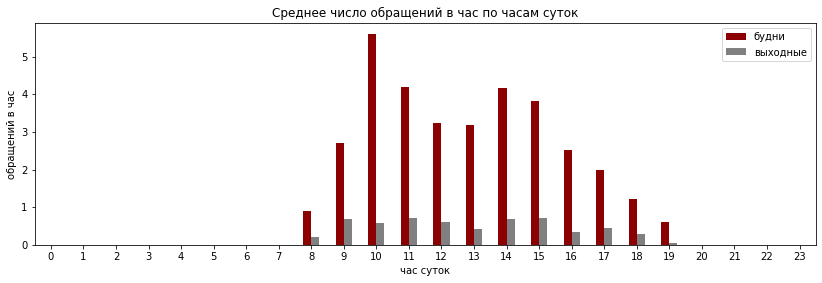

hour,7,8,9,10,11,12,13,14,15,16,17,18,19,20
будни,0.0,0.91,2.69,5.61,4.18,3.24,3.18,4.16,3.81,2.52,1.98,1.21,0.61,0.0
выходные,0.0,0.21,0.69,0.58,0.71,0.60,0.42,0.69,0.71,0.35,0.44,0.29,0.06,0.0


In [22]:
hourly = appeals.groupby('hour').size().reindex(periods_of(appeals, 'hour'), fill_value=0)
day_type = np.where(hourly.index.weekday >= 5, 'выходные', 'будни')
by_hour = hourly.groupby([hourly.index.hour, day_type]).mean().unstack()

by_hour.plot(kind='bar', figsize=(14, 4), color=['darkred', 'grey'])
plt.title('Среднее число обращений в час по часам суток')
plt.xlabel('час суток')
plt.ylabel('обращений в час')
plt.xticks(rotation=0)
plt.show()

by_hour.loc[7:20].round(2).T

**Вывод:** обращения приходят с 8 до 20 часов, пик в будни — 10–11 часов, около 5–6 обращений в час
на весь поток; ночью обращений нет. По отдельному значению признака за час почти всегда ноль. Поэтому норма
для часа считается по тому же часу суток, а пороги нужны строже, чем для дня

**Пороги для часа.** За час обращений мало, а проверок в 24 раза больше, чем для дня. При уровне 0,01%
случайных срабатываний было бы около 60 — поэтому для часа уровень строже:
- не меньше 5 обращений за час;
- хотя бы вдвое больше нормы;
- вероятность получить столько случайно меньше 0,0001%.

Норма «почти ноль» по-прежнему считается равной 0,5 обращения — для часа это осторожная оценка:
при ней всплеском считается 8 и больше обращений за час по одному значению

In [23]:
display(f'Норма 0,5 в час: P(≥7) = {poisson_tail(7, 0.5):.5%}, P(≥8) = {poisson_tail(8, 0.5):.5%}')

'Норма 0,5 в час: P(≥7) = 0.00010%, P(≥8) = 0.00001%'

In [24]:
alerts_hourly = detect(appeals, alerts_start, window='hour')

display(f'Уведомлений: {len(alerts_hourly)}, дней с уведомлениями: {alerts_hourly["date"].nunique()}')
alerts_hourly.groupby('feature').size()

'Уведомлений: 100, дней с уведомлениями: 11'

,0
feature,
interface,20
interface × topic,22
product,13
product × topic,22
topic,23


Один инцидент длится несколько часов и каждый час поднимает несколько признаков. Для поддержки главное —
первое уведомление: когда о проблеме стало известно. Сводка по дням: первый час с уведомлением, самое точное
уведомление в нём и сколько часов за день были уведомления

In [25]:
first_hourly = (alerts_hourly.assign(is_combination=alerts_hourly['feature'].str.contains('×'))
                .sort_values(['hour', 'is_combination', 'ratio'], ascending=[True, False, False])
                .groupby('date').head(1).set_index('date'))
first_hourly['hours_with_alerts'] = alerts_hourly.groupby('date')['hour'].nunique()
first_hourly[['hour', 'feature', 'value', 'count', 'usual', 'ratio', 'hours_with_alerts']]

,hour,feature,value,count,usual,ratio,hours_with_alerts
date,,,,,,,
2026-07-08,10:00–11:00,interface × topic,API × DATA_MISSING,14,0.5,28.0,3
2026-09-03,10:00–11:00,interface × topic,EXCEL_TEMPLATE × AVAILABILITY,12,0.0,24.0,1
2026-09-16,10:00–11:00,interface × topic,EFIR × PERFORMANCE,12,0.0,24.0,2
2026-09-23,10:00–11:00,product × topic,RD_AFFILIATE × AVAILABILITY,11,0.1,22.0,2
2026-09-09,10:00–11:00,interface × topic,API × PERFORMANCE,10,0.0,20.0,4
2026-05-13,10:00–11:00,interface × topic,EXCEL_TEMPLATE × DATA_MISSING,9,0.2,18.0,2
2026-08-18,11:00–12:00,interface × topic,WEB × AUTH_ACCESS,10,0.0,20.0,3
2026-06-04,12:00–13:00,interface × topic,EXCEL_ADDIN × DATA_MISSING,12,0.0,24.0,2
2026-08-06,12:00–13:00,interface × topic,WEB × PERFORMANCE,8,0.0,16.0,2


Первое уведомление за каждый день — в том виде, в каком его получит поддержка

In [26]:
for _, alert in first_hourly.reset_index().iterrows():
    print(notification(alert))

08.07.2026 10:00–11:00 | interface × topic = API × DATA_MISSING: обращений за час — 14, обычно меньше 1 в час, в 28 раз больше нормы
03.09.2026 10:00–11:00 | interface × topic = EXCEL_TEMPLATE × AVAILABILITY: обращений за час — 12, обычно меньше 1 в час, в 24 раза больше нормы
16.09.2026 10:00–11:00 | interface × topic = EFIR × PERFORMANCE: обращений за час — 12, обычно меньше 1 в час, в 24 раза больше нормы
23.09.2026 10:00–11:00 | product × topic = RD_AFFILIATE × AVAILABILITY: обращений за час — 11, обычно меньше 1 в час, в 22 раза больше нормы
09.09.2026 10:00–11:00 | interface × topic = API × PERFORMANCE: обращений за час — 10, обычно меньше 1 в час, в 20 раз больше нормы
13.05.2026 10:00–11:00 | interface × topic = EXCEL_TEMPLATE × DATA_MISSING: обращений за час — 9, обычно меньше 1 в час, в 18 раз больше нормы
18.08.2026 11:00–12:00 | interface × topic = WEB × AUTH_ACCESS: обращений за час — 10, обычно меньше 1 в час, в 20 раз больше нормы
04.06.2026 12:00–13:00 | interface × top

Как выглядит всплеск по часам: самый крупный инцидент, 9 сентября, число обращений по часам и норма

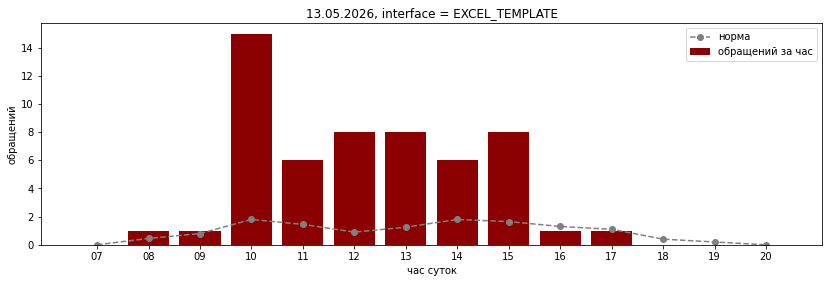

In [27]:
top_hourly = alerts_hourly.sort_values('count', ascending=False).iloc[0]
feature = top_hourly['feature'].split(' × ')
counts = counts_by(appeals, feature, 'hour')
norm = baseline(counts)
day_hours = [p for p in counts.index if p.date() == top_hourly['date'] and 7 <= p.hour <= 20]

plt.figure(figsize=(14, 4))
plt.bar([f'{p:%H}' for p in day_hours], counts.loc[day_hours, top_hourly['value']], color='darkred', label='обращений за час')
plt.plot([f'{p:%H}' for p in day_hours], norm.loc[day_hours, top_hourly['value']], color='grey', linestyle='--',
         marker='o', label='норма')
plt.title(f'{top_hourly["date"]:%d.%m.%Y}, {top_hourly["feature"]} = {top_hourly["value"]}')
plt.xlabel('час суток')
plt.ylabel('обращений')
plt.legend()
plt.show()

### Сравнение с дневным окном

Какие дни нашло каждое окно и когда приходит первое уведомление. Дневное — после окончания дня,
почасовое — в конце первого часа со всплеском

In [28]:
comparison = pd.DataFrame({'день: уведомление': summary.set_index('date')['value'],
                           'час: первое уведомление': first_hourly['hour'],
                           'час: значение': first_hourly['value'],
                           'час: часов с уведомлениями': first_hourly['hours_with_alerts']})
comparison.sort_index().fillna('—')

,день: уведомление,час: первое уведомление,час: значение,час: часов с уведомлениями
date,,,,
2026-05-13,RD_SCORE × DATA_MISSING,10:00–11:00,EXCEL_TEMPLATE × DATA_MISSING,2.0
2026-05-27,API,—,—,—
2026-06-04,EXCEL_ADDIN × DATA_MISSING,12:00–13:00,EXCEL_ADDIN × DATA_MISSING,2.0
2026-07-08,API × DATA_MISSING,10:00–11:00,API × DATA_MISSING,3.0
2026-07-22,EFIR × AUTH_ACCESS,14:00–15:00,AUTH_ACCESS,1.0
2026-08-03,EXCEL_TEMPLATE × METHODOLOGY,—,—,—
2026-08-04,EXCEL_TEMPLATE × HOW_TO,—,—,—
2026-08-06,WEB × PERFORMANCE,12:00–13:00,WEB × PERFORMANCE,2.0
2026-08-18,WEB × AUTH_ACCESS,11:00–12:00,WEB × AUTH_ACCESS,3.0


**Вывод:** почасовое окно нашло 11 из 12 явных инцидентов. В 6 из них первое уведомление пришло
в 11:00 — по итогам первого часа роста, в остальных — с 12:00 до 15:00. Дневное окно сообщает о тех же
инцидентах только после окончания дня.

Почасовое окно не нашло:
- 29.09, API × DATA_DISCREPANCY: 21 обращение растянуто на весь день, не больше 6 в час. Для каждого часа
  это мало, а за день — явный рост;
- три слабых дня 27.05, 03.08 и 04.08 — кандидатов в ложные срабатывания дневного окна.

Окна дополняют друг друга: почасовое — для быстрой реакции на резкий сбой, дневное — чтобы не пропустить
медленный рост за день

### Ложные срабатывания почасового окна

Та же оценка, что для дня: проверок — «число часов × число значений», ожидаемо случайных срабатываний —
не больше «проверок × alpha»

In [29]:
hours_checked = [p for p in periods_of(appeals, 'hour') if p >= pd.Timestamp(alerts_start)]
n_checks_hourly = sum(counts_by(appeals, feature, 'hour').shape[1] for feature in FEATURES) * len(hours_checked)
display(f'Проверок за период: {n_checks_hourly}, ожидаемо случайных срабатываний — '
        f'не больше {n_checks_hourly * WINDOWS["hour"]["alpha"]:.1f}')

'Проверок за период: 606360, ожидаемо случайных срабатываний — не больше 0.6'

In [30]:
sensitivity_hourly = []
for alpha in [0.0001, 0.00001, 0.000001, 0.0000001]:
    found = detect(appeals, alerts_start, window='hour', alpha=alpha)
    sensitivity_hourly.append({'alpha': alpha, 'alerts': len(found), 'days': found['date'].nunique(),
                               'expected_random': round(n_checks_hourly * alpha, 1)})

pd.DataFrame(sensitivity_hourly)

,alpha,alerts,days,expected_random
0,1.000000e-04,172,13,60.6
1,1.000000e-05,130,12,6.1
2,1.000000e-06,100,11,0.6
3,1.000000e-07,92,11,0.1


При уровне 0,001% (`alpha` = 0,00001) добавляется 29.09, но случайных срабатываний ожидается уже около 6;
при 0,01% — ещё и слабый день 27.05 при 60 ожидаемых случайных. Выбран уровень 0,0001%: случайно за период
ожидается меньше одного срабатывания, а медленный рост вроде 29.09 находит дневное окно

### Сквозной сценарий: почасовое окно на прогнозах

Те же прогнозы гибрида: август — накопление нормы, уведомления сравниваются за сентябрь

In [31]:
predicted_hourly = predicted.merge(appeals[['appeal_id', 'hour']], on='appeal_id')
alerts_hourly_predicted = detect(predicted_hourly, september[0], window='hour')
alerts_hourly_gold_september = alerts_hourly[alerts_hourly['date'] >= september[0]]


def hourly_keys(data):
    return set(zip(data['date'], data['hour'], data['feature'], data['value']))


gold_keys_hourly, predicted_keys_hourly = hourly_keys(alerts_hourly_gold_september), hourly_keys(alerts_hourly_predicted)
display(f'Сентябрь: на эталоне {len(gold_keys_hourly)} уведомлений, на прогнозах {len(predicted_keys_hourly)}')
display(f'Совпали: {len(gold_keys_hourly & predicted_keys_hourly)}, '
        f'пропущены: {len(gold_keys_hourly - predicted_keys_hourly)}, лишние: {len(predicted_keys_hourly - gold_keys_hourly)}')

'Сентябрь: на эталоне 39 уведомлений, на прогнозах 38'

'Совпали: 38, пропущены: 1, лишние: 0'

Совпадают ли первые уведомления по дням — именно они важны для поддержки

In [32]:
first_predicted = alerts_hourly_predicted.groupby('date')['hour'].min()
first_gold = alerts_hourly_gold_september.groupby('date')['hour'].min()
pd.DataFrame({'эталон: первое уведомление': first_gold, 'прогнозы: первое уведомление': first_predicted}).fillna('—')

,эталон: первое уведомление,прогнозы: первое уведомление
date,,
2026-09-03,10:00–11:00,10:00–11:00
2026-09-09,10:00–11:00,10:00–11:00
2026-09-16,10:00–11:00,10:00–11:00
2026-09-23,10:00–11:00,10:00–11:00


**Вывод:** на прогнозах гибрида почасовое окно воспроизвело 38 из 39 уведомлений эталона за сентябрь,
лишних нет, первое уведомление во все 4 дня — в тот же час, что и на эталоне. Пропущено одно: 03.09
в 10:00–11:00 одно обращение классификатор отнёс к интерфейсу `UNKNOWN`, и по интерфейсу EXCEL_TEMPLATE
стало 11 обращений вместо 12 — ниже порога. Более точное уведомление по сочетанию
«EXCEL_TEMPLATE × AVAILABILITY» в этот час сработало и на прогнозах

## Сохранение результатов

In [33]:
alerts.assign(notification=alerts.apply(notification, axis=1)).to_csv(
    'results/spikes_gold.csv', index=False, encoding='utf-8-sig')
alerts_predicted.assign(notification=alerts_predicted.apply(notification, axis=1)).to_csv(
    'results/spikes_predicted_september.csv', index=False, encoding='utf-8-sig')
alerts_hourly.assign(notification=alerts_hourly.apply(notification, axis=1)).to_csv(
    'results/spikes_hourly_gold.csv', index=False, encoding='utf-8-sig')
alerts_hourly_predicted.assign(notification=alerts_hourly_predicted.apply(notification, axis=1)).to_csv(
    'results/spikes_hourly_predicted_september.csv', index=False, encoding='utf-8-sig')

## Выводы

- **Метод.** Две версии окна — календарный день и календарный час. Норма — среднее за 28 предыдущих дней
  того же типа (будни или выходные), для часа — в тот же час суток; только по прошлому, первые 28 дней истории —
  накопление нормы. Всплеск — хотя бы вдвое больше нормы, не меньше 10 обращений за день или 5 за час,
  и вероятность получить столько случайно меньше 0,01% для дня и 0,0001% для часа (распределение Пуассона).
  Отслеживаются отдельные поля и сочетания «интерфейс × тематика», «продукт × тематика».

**Дневное окно**
- **Эталонная разметка, май–сентябрь:** 63 уведомления в 15 днях. В 12 днях — явные инциденты: 21–50 обращений
  по одному сочетанию при обычных 0–1 в день. Например, 09.09 — 50 жалоб на скорость API, 16.09 — 47 жалоб
  на скорость ЭФИР, 18.08 — 45 проблем со входом на сайт.
- **Кандидаты в ложные срабатывания** — 3 более слабых уведомления: 27.05 (API — 14 обращений при норме 3,7),
  03.08 и 04.08 (10–11 вопросов по методологии и работе с шаблонами при норме около нуля). В начале августа
  меняется состав потока, а не происходит сбой. Это согласуется с оценкой: случайно за период ожидается
  не больше 2–3 срабатываний. При уровне 0,1% случайных срабатываний ожидалось бы около 25, поэтому выбран 0,01%.
- **Сквозной сценарий** (сентябрь, прогнозы гибрида): все 24 уведомления эталона воспроизведены, пропусков нет.
  Два лишних (14.09 и 15.09) — пограничные: число обращений то же, что на эталоне, а норма по прогнозам августа
  немного ниже эталонной.

**Почасовое окно**
- **Эталонная разметка:** 100 уведомлений в 11 днях — 11 из 12 явных инцидентов, слабых дней среди них нет.
  В 6 инцидентах первое уведомление пришло в 11:00, по итогам первого часа роста, в остальных — с 12:00 до 15:00,
  а не после окончания дня. Случайно за период ожидается меньше одного срабатывания.
- **Чего не видит:** 29.09 — 21 обращение по API × DATA_DISCREPANCY растянуто на весь день, не больше 6 в час.
  Такой медленный рост находит только дневное окно.
- **Сквозной сценарий** (сентябрь): 38 из 39 уведомлений эталона, лишних нет; первое уведомление во все 4 дня —
  в тот же час, что и на эталоне.

**Рекомендация:** использовать оба окна вместе. Почасовое — для быстрой реакции на резкий сбой в течение
рабочего дня, дневное — итоговая сводка, которая ловит медленный рост.

**Ограничения.** Флагов инцидентов в данных нет, поэтому полноту обнаружения подтвердить нельзя — только оценкой
ожидаемого числа случайных срабатываний и разбором примеров. Пороги подобраны на синтетическом потоке
около 26 обращений в день; на реальных данных их нужно проверить, в первую очередь для часа: при большем потоке
порог 5 обращений за час можно поднять. При изменении состава потока пороги нужно пересматривать.